# Calibration Errors and Trading Opportunities in Kalshi Political Speech Mention Markets

**Abstract.** This notebook examines persistent calibration errors in political speech mention markets on Kalshi, a CFTC-regulated prediction exchange. The dataset covers ~18,000+ resolved binary contracts across political speech mention series, which we divide into four subgroups for analysis:

1. **Trump Markets** -- the highest-volume series, centered on mentions during Trump speeches and rallies.
2. **Press Briefings** -- White House Secretary of the Press daily briefing mention contracts.
3. **Mamdani / NYC Mayoral** -- mention markets around Zohran Mamdani and the NYC mayoral race.
4. **Niche / One-offs** -- lower-volume political mention markets (Biden, Vance, Walz, AOC, etc.).

We measure calibration at multiple VWAP horizons, quantify directional accuracy, and backtest simple threshold strategies that exploit the observed longshot bias -- all net of Kalshi's taker fee schedule.

---
## 0. Setup

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

from src.data_loading import load_mention_markets, load_trade_positions, VWAP_INTERVALS
from src.mention_filters import (
    get_category, assign_political_subgroup, POLITICAL_SERIES
)
from src.metrics import (
    kalshi_fee, calibration_buckets, compute_mad, multi_horizon_calibration,
    strategy_profits, extremes_strategy, calibration_deviation_over_time
)
from src.plotting import (
    apply_style, plot_calibration_curve, plot_multi_horizon_calibration,
    plot_faceted_calibration, plot_mad_summary, plot_vwap_traces,
    plot_calibration_deviation_over_time, plot_strategy_comparison,
    plot_profit_heatmap, C_BLUE, C_GREEN, C_RED, C_GRAY, C_LIGHTBLUE
)

apply_style()

---
## 1. Load Data

We start by loading **all** resolved mention markets from the parquet data on the T7 SSD (symlinked under `data/`), then filter down to the **Politicians** category. Each contract is assigned to one of four political subgroups. The 2-hour VWAP serves as our primary implied-probability snapshot.

In [2]:
print("Loading mention market data...")
df_all = load_mention_markets()
print(f"Loaded {len(df_all)} total mention contracts")

# Filter to political mention series
df_all["category"] = df_all["series"].apply(get_category)
df_mention = df_all[df_all["category"] == "Politicians"].copy()
df_mention["subgroup"] = df_mention["series"].apply(assign_political_subgroup)
df_mention["actual_yes"] = df_mention["result"] == "yes"
df_mention = df_mention.dropna(subset=["vwap_2h"]).copy()

# Directional accuracy
df_mention["predicted_yes"] = df_mention["vwap_2h"] > 50.0
df_mention["correct"] = df_mention["predicted_yes"] == df_mention["actual_yes"]

print(f"Political mention contracts: {len(df_mention)}")
print(f"Subgroup distribution:")
print(df_mention["subgroup"].value_counts().to_string())

Loading mention market data...
Loaded 18948 total mention contracts
Political mention contracts: 7745
Subgroup distribution:
subgroup
Group 1: Trump Markets               3462
Group 4: Niche / One-offs            2293
Group 2: Press Briefings             1058
Group 3: Mayoral (Zohran Mamdani)     932


---
## 2. Calibration Deviation Over Time

Before looking at static calibration curves, we examine how calibration accuracy has evolved over the life of these markets. At each weekly snapshot, we compute the **cumulative mean absolute deviation** (MAD) between the price at which positions were acquired and their actual win rate. This reveals whether the market has been learning and converging toward fair pricing, or whether systematic biases persist.

We require a minimum of 500 cumulative trade positions before the first data point to avoid noisy early estimates.

Loading trade positions for calibration over time analysis...
Loaded 4708548 trade positions


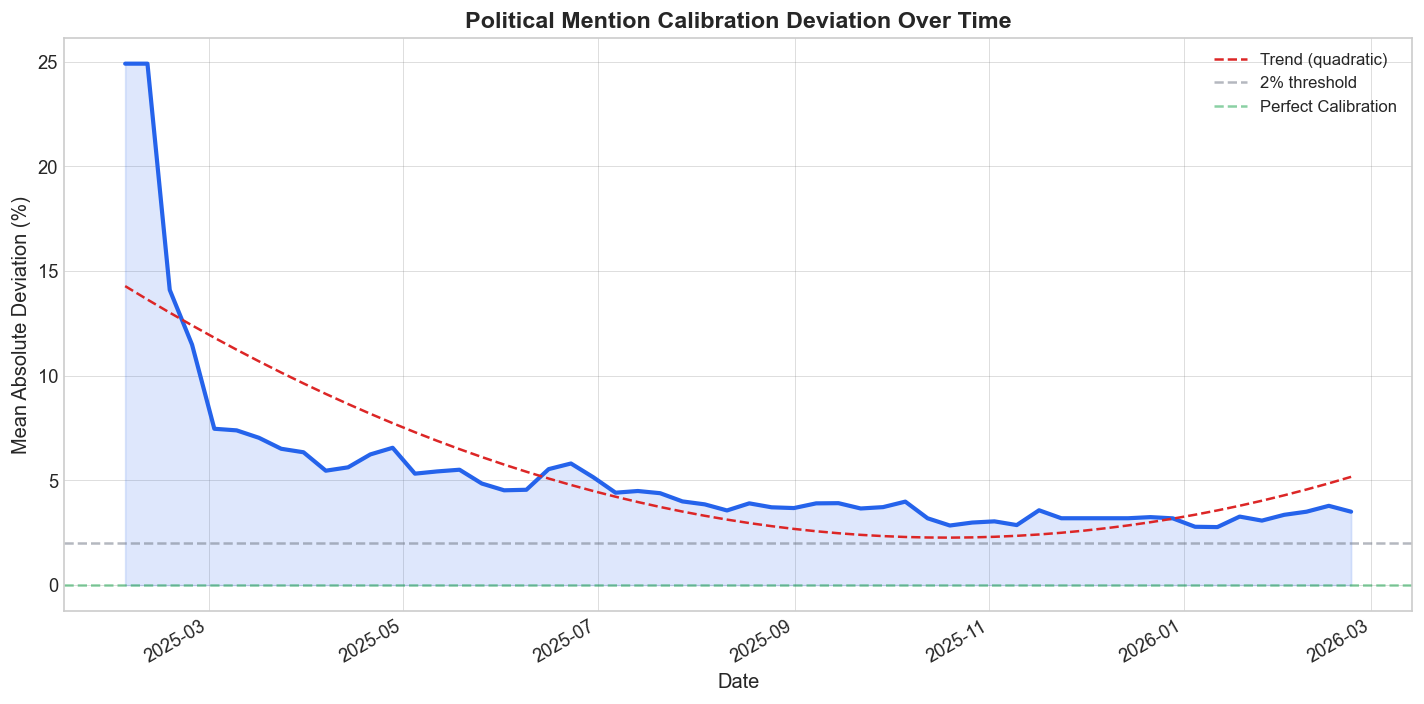

In [3]:
# Load trade positions for calibration over time
print("Loading trade positions for calibration over time analysis...")
df_positions = load_trade_positions()
df_positions["category"] = df_positions["series"].apply(get_category)
df_positions = df_positions[df_positions["category"] == "Politicians"].copy()
print(f"Loaded {len(df_positions)} trade positions")

# Compute cumulative calibration deviation
df_cal = calibration_deviation_over_time(df_positions, min_cumulative=500)

fig = plot_calibration_deviation_over_time(
    df_cal,
    title="Political Mention Calibration Deviation Over Time",
    show_trend=True,
)
plt.show()

In [4]:
print("=== Political Mention Calibration Deviation Over Time ===")
print(f"Mean absolute deviation (overall): {df_cal['mean_absolute_deviation'].mean():.2f} percentage points")
print(f"Early period (first 8 weeks):      {df_cal['mean_absolute_deviation'].head(8).mean():.2f} %")
print(f"Recent period (last 8 weeks):       {df_cal['mean_absolute_deviation'].tail(8).mean():.2f} %")
slope = np.polyfit(range(len(df_cal)), df_cal["mean_absolute_deviation"], 1)[0]
print(f"\nTrend: {slope:.3f} percentage points/week ({'improving' if slope < 0 else 'worsening'})")

=== Political Mention Calibration Deviation Over Time ===
Mean absolute deviation (overall): 5.35 percentage points
Early period (first 8 weeks):      12.97 %
Recent period (last 8 weeks):       3.26 %

Trend: -0.166 percentage points/week (improving)


---
## 3. Overall Calibration Curve

A calibration curve plots the **actual YES resolution rate** against the **market-implied probability** (here, the 2-hour VWAP). A perfectly calibrated market would fall exactly on the 45-degree diagonal: contracts priced at 70 cents would resolve YES 70% of the time.

We use 10-cent buckets to aggregate contracts and overlay shaded zones highlighting where the market systematically misprices outcomes -- green for the high end (potential over-confidence) and red for the low end (longshot bias).

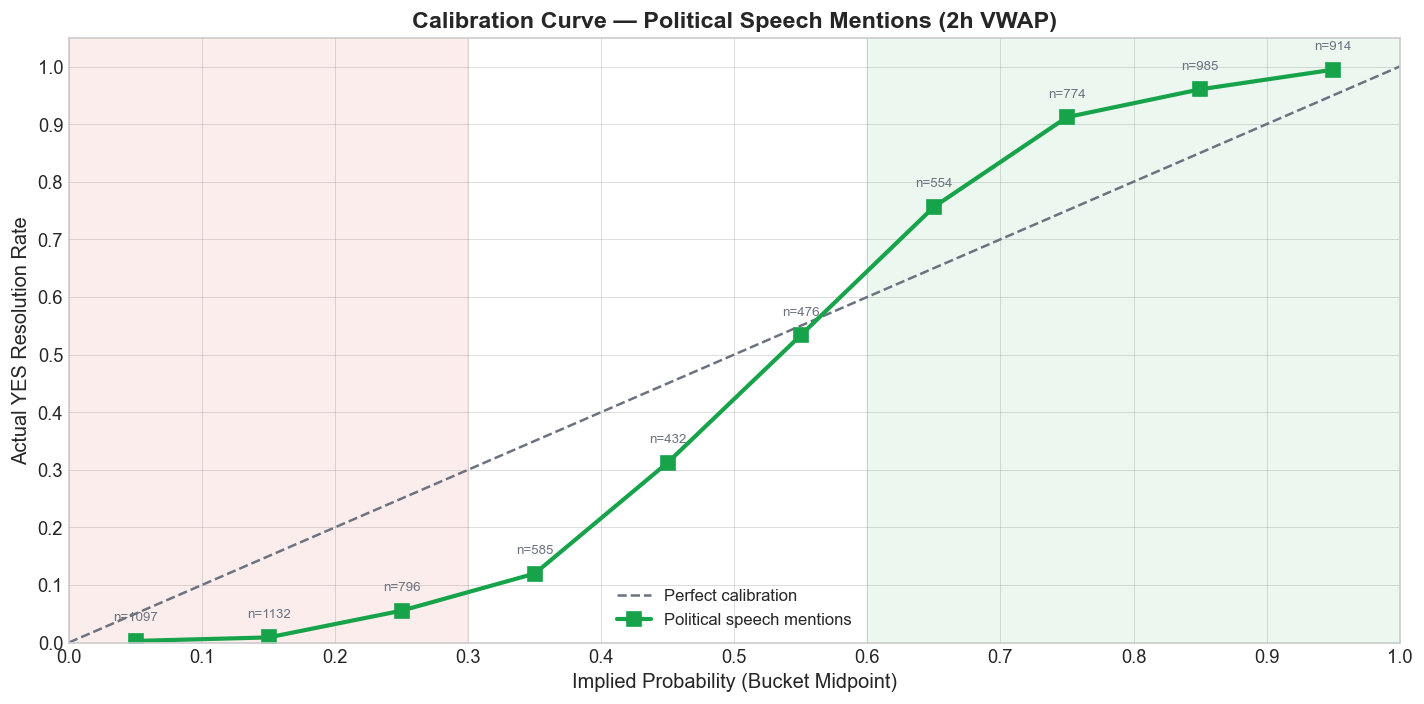

In [5]:
# Overall political mention calibration using 2h VWAP
cal_pol = calibration_buckets(df_mention, "vwap_2h", bin_size=10)

fig, ax = plt.subplots(figsize=(12, 6))
ax = plot_calibration_curve(cal_pol, ax=ax, label="Political speech mentions", color=C_GREEN, marker="s")
ax.set_xlabel("Implied Probability (Bucket Midpoint)", fontsize=12)
ax.set_ylabel("Actual YES Resolution Rate", fontsize=12)
ax.set_title("Calibration Curve \u2014 Political Speech Mentions (2h VWAP)", fontsize=14, fontweight="bold")

# Highlight exploitable zones
ax.axvspan(0.60, 1.0, alpha=0.08, color=C_GREEN, zorder=1)
ax.axvspan(0.0, 0.30, alpha=0.08, color=C_RED, zorder=1)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
## 4. Directional Accuracy by Subgroup

**Directional accuracy** measures the simplest possible prediction: does the 2-hour VWAP correctly predict the market outcome? If the VWAP exceeds 50 cents we predict YES; otherwise NO. A market with any predictive content should exceed 50%, and a well-calibrated market should score well above that.

We compute directional accuracy for each of the four political subgroups and overlay the contract count to contextualize statistical reliability.

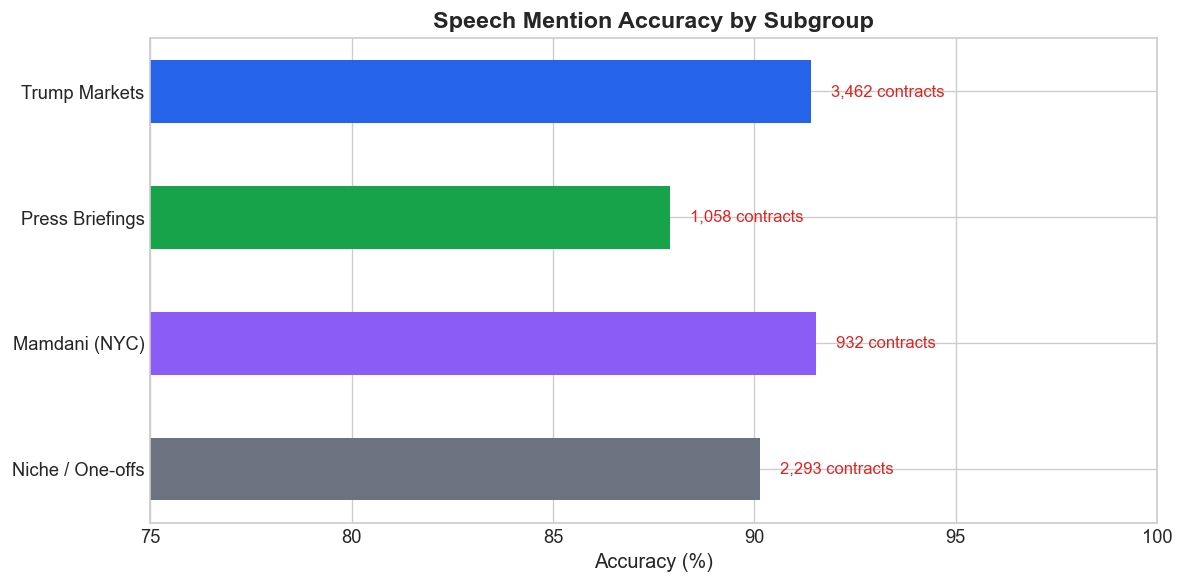

In [6]:
subgroups = ["Group 1: Trump Markets", "Group 2: Press Briefings",
             "Group 3: Mayoral (Zohran Mamdani)", "Group 4: Niche / One-offs"]

df_sub = []
for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g]
    acc = g_df["correct"].mean()
    tot = len(g_df)
    
    # Strategy profits
    strat = strategy_profits(g_df, thresholds=[60, 70, 80, 90])
    ext = extremes_strategy(g_df)
    
    row = {
        "subgroup": g,
        "total_mention_contracts": tot,
        "accuracy": acc,
        "ext_trades": ext["trades"],
        "ext_profit": ext["net_return"],
    }
    for _, s in strat.iterrows():
        t = int(s["threshold"])
        row[f"gt{t}_trades"] = int(s["trades"])
        row[f"gt{t}_profit"] = s["net_return"]
    df_sub.append(row)

df_sub = pd.DataFrame(df_sub)

# Accuracy bar chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = [C_BLUE, C_GREEN, "#8b5cf6", C_GRAY]
short_labels = ["Trump Markets", "Press Briefings", "Mamdani (NYC)", "Niche / One-offs"]
bars = ax.barh(short_labels[::-1], df_sub["accuracy"].values[::-1] * 100, color=colors[::-1], height=0.5)
for bar, n in zip(bars, df_sub["total_mention_contracts"].values[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{n:,} contracts", va="center", fontsize=10, color=C_RED)
ax.set_xlabel("Accuracy (%)", fontsize=12)
ax.set_title("Speech Mention Accuracy by Subgroup", fontsize=14, fontweight="bold")
ax.set_xlim(75, 100)
plt.tight_layout()
plt.show()

---
## 5. Subgroup Calibration Deep Dives

Each subgroup has distinct market dynamics. Below we produce faceted calibration charts for every subgroup, showing how the calibration curve behaves across three bucket granularities (1-cent, 5-cent, and 10-cent) and six VWAP horizons (1 day, 6 hours, 2 hours, 1 hour, 30 minutes, 10 minutes).

### 5.1 Group 1: Trump Markets

The Trump mention series (`KXTRUMPMENTION`) is by far the most liquid and highest-volume political mention market. These contracts resolve based on whether specific words or phrases are mentioned during Trump rallies, press conferences, and other public appearances. The high volume provides the most statistically robust calibration estimates.

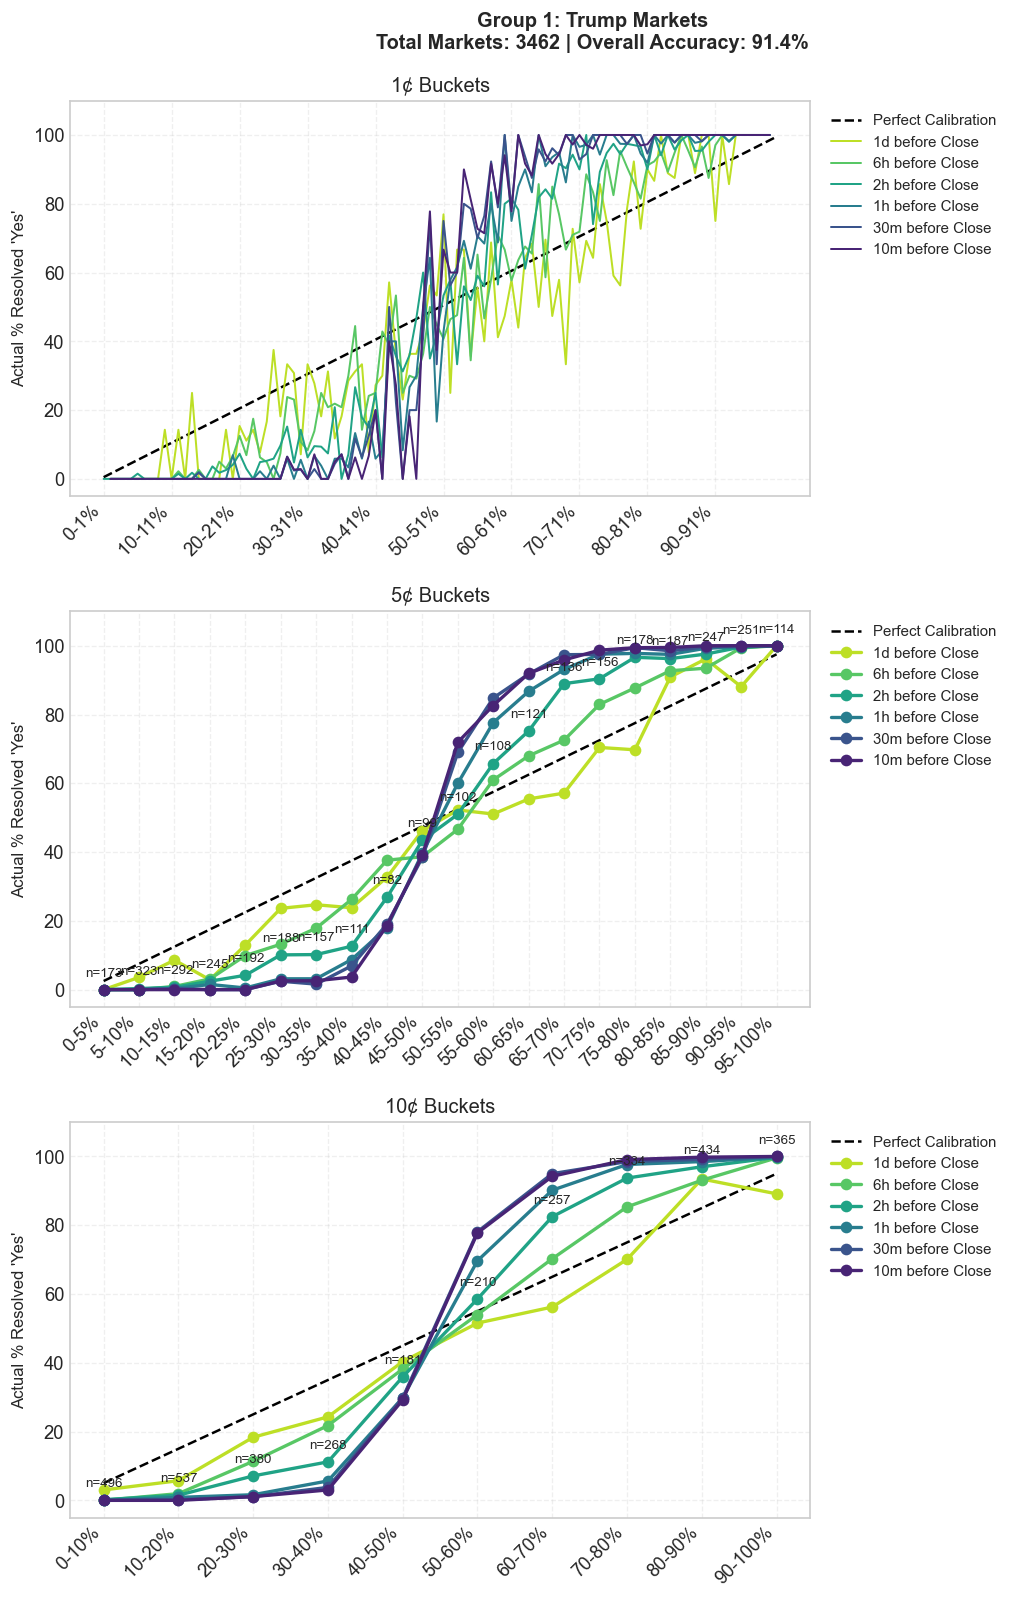

In [7]:
# Group 1: Trump Markets
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]
trump_row = df_sub[df_sub["subgroup"] == "Group 1: Trump Markets"].iloc[0]
trump_df = df_mention[df_mention["subgroup"] == "Group 1: Trump Markets"].copy()
fig = plot_faceted_calibration(trump_df, "Group 1: Trump Markets",
    int(trump_row["total_mention_contracts"]), trump_row["accuracy"], intervals)
plt.show()

### 5.2 Group 2: Press Briefings

White House Secretary of the Press briefing mention contracts (`KXSECPRESSMENTION`) cover daily briefings. These are notable for their regularity -- briefings happen on a predictable schedule -- and the relatively constrained vocabulary. This subgroup tests whether routine, recurring events are priced more efficiently than ad-hoc speeches.

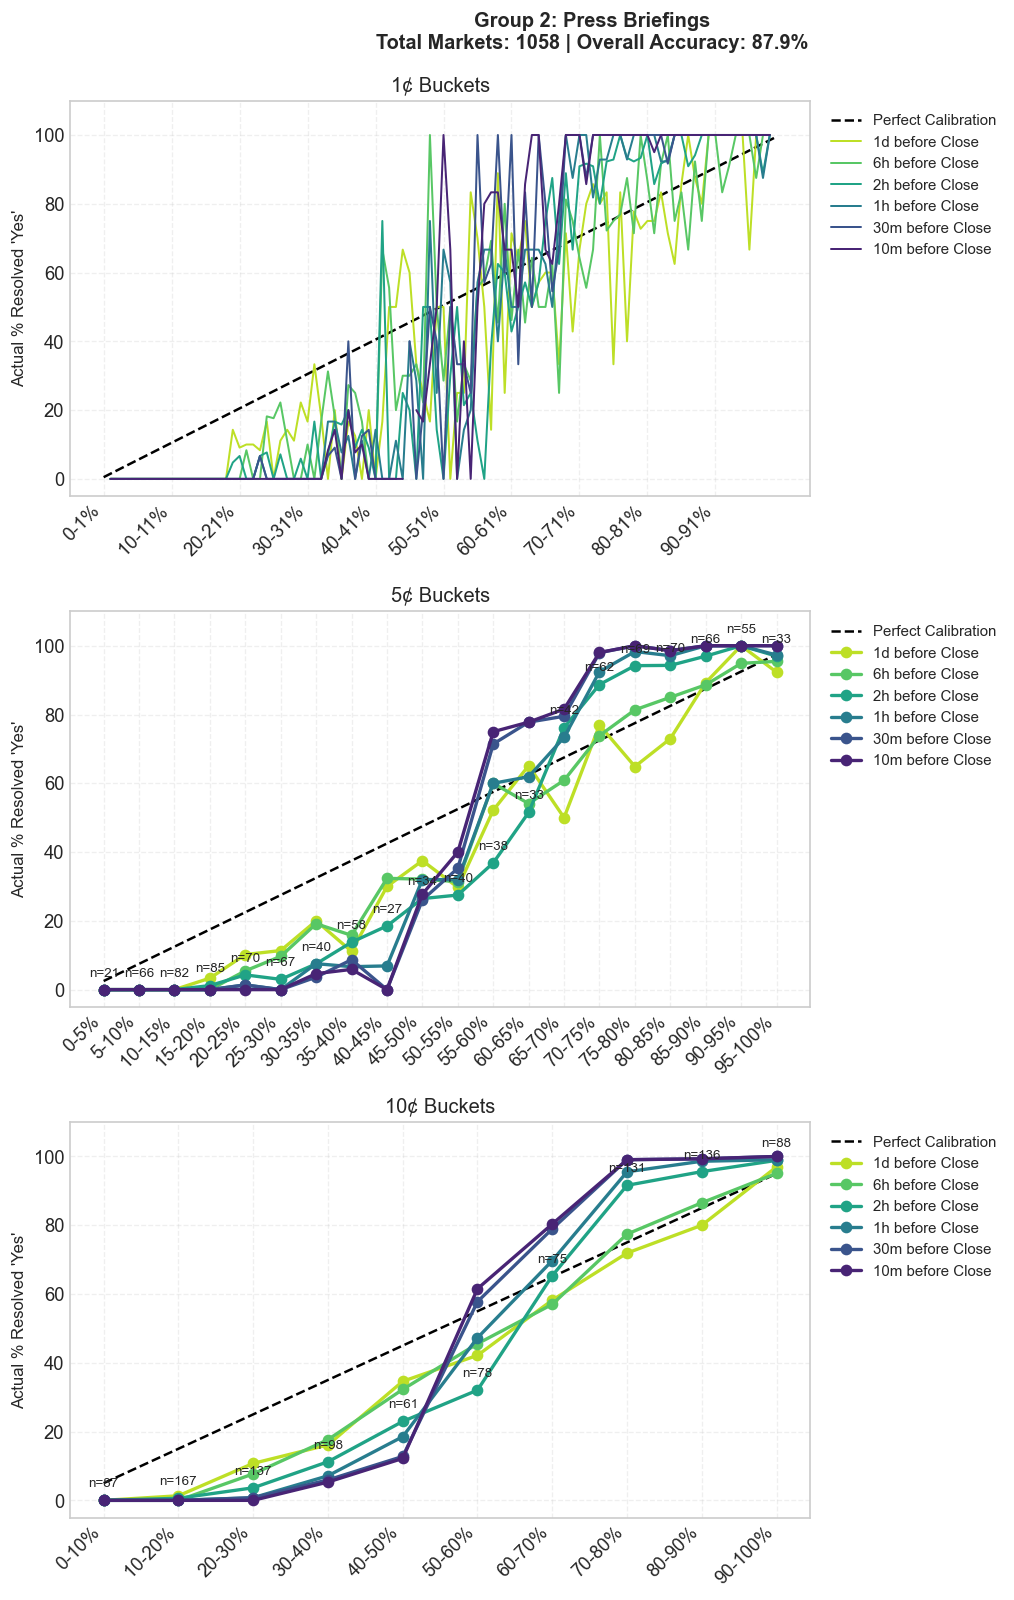

In [8]:
# Group 2: Press Briefings
press_row = df_sub[df_sub["subgroup"] == "Group 2: Press Briefings"].iloc[0]
press_df = df_mention[df_mention["subgroup"] == "Group 2: Press Briefings"].copy()
fig = plot_faceted_calibration(press_df, "Group 2: Press Briefings",
    int(press_row["total_mention_contracts"]), press_row["accuracy"], intervals)
plt.show()

### 5.3 Group 3: Mamdani / NYC Mayoral

The Zohran Mamdani and NYC mayoral debate mention series (`KXMAMDANIMENTION`, `KXNYCMAYORDEBATEMENTION`) represent a niche but active political mention market. Given the lower national profile compared to Trump or White House briefings, we might expect thinner liquidity and potentially larger calibration errors.

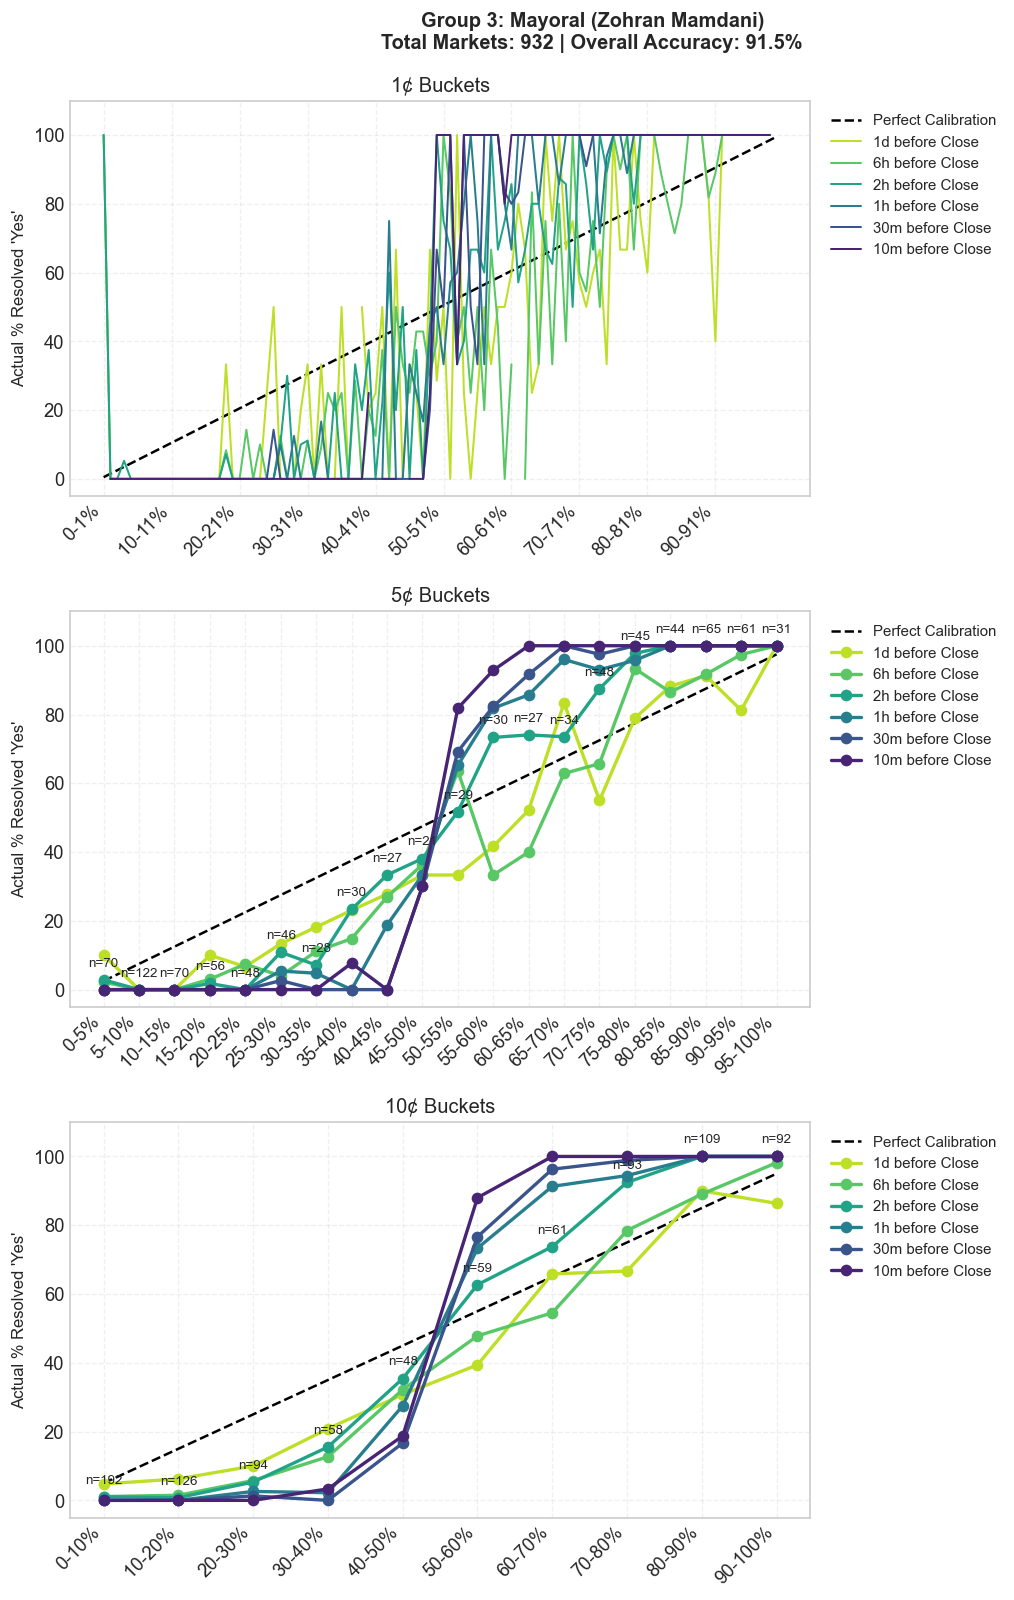

In [9]:
# Group 3: Mayoral (Zohran Mamdani)
mamdani_row = df_sub[df_sub["subgroup"] == "Group 3: Mayoral (Zohran Mamdani)"].iloc[0]
mamdani_df = df_mention[df_mention["subgroup"] == "Group 3: Mayoral (Zohran Mamdani)"].copy()
fig = plot_faceted_calibration(mamdani_df, "Group 3: Mayoral (Zohran Mamdani)",
    int(mamdani_row["total_mention_contracts"]), mamdani_row["accuracy"], intervals)
plt.show()

### 5.4 Group 4: Niche / One-offs

This residual category includes all other political mention series: Biden, Vance, Bernie Sanders, AOC, Hegseth, Hochul, DeSantis, and many more. Each individual series may have limited sample size, but in aggregate they reveal whether the calibration patterns observed in the high-volume series generalize to the long tail of political mention markets.

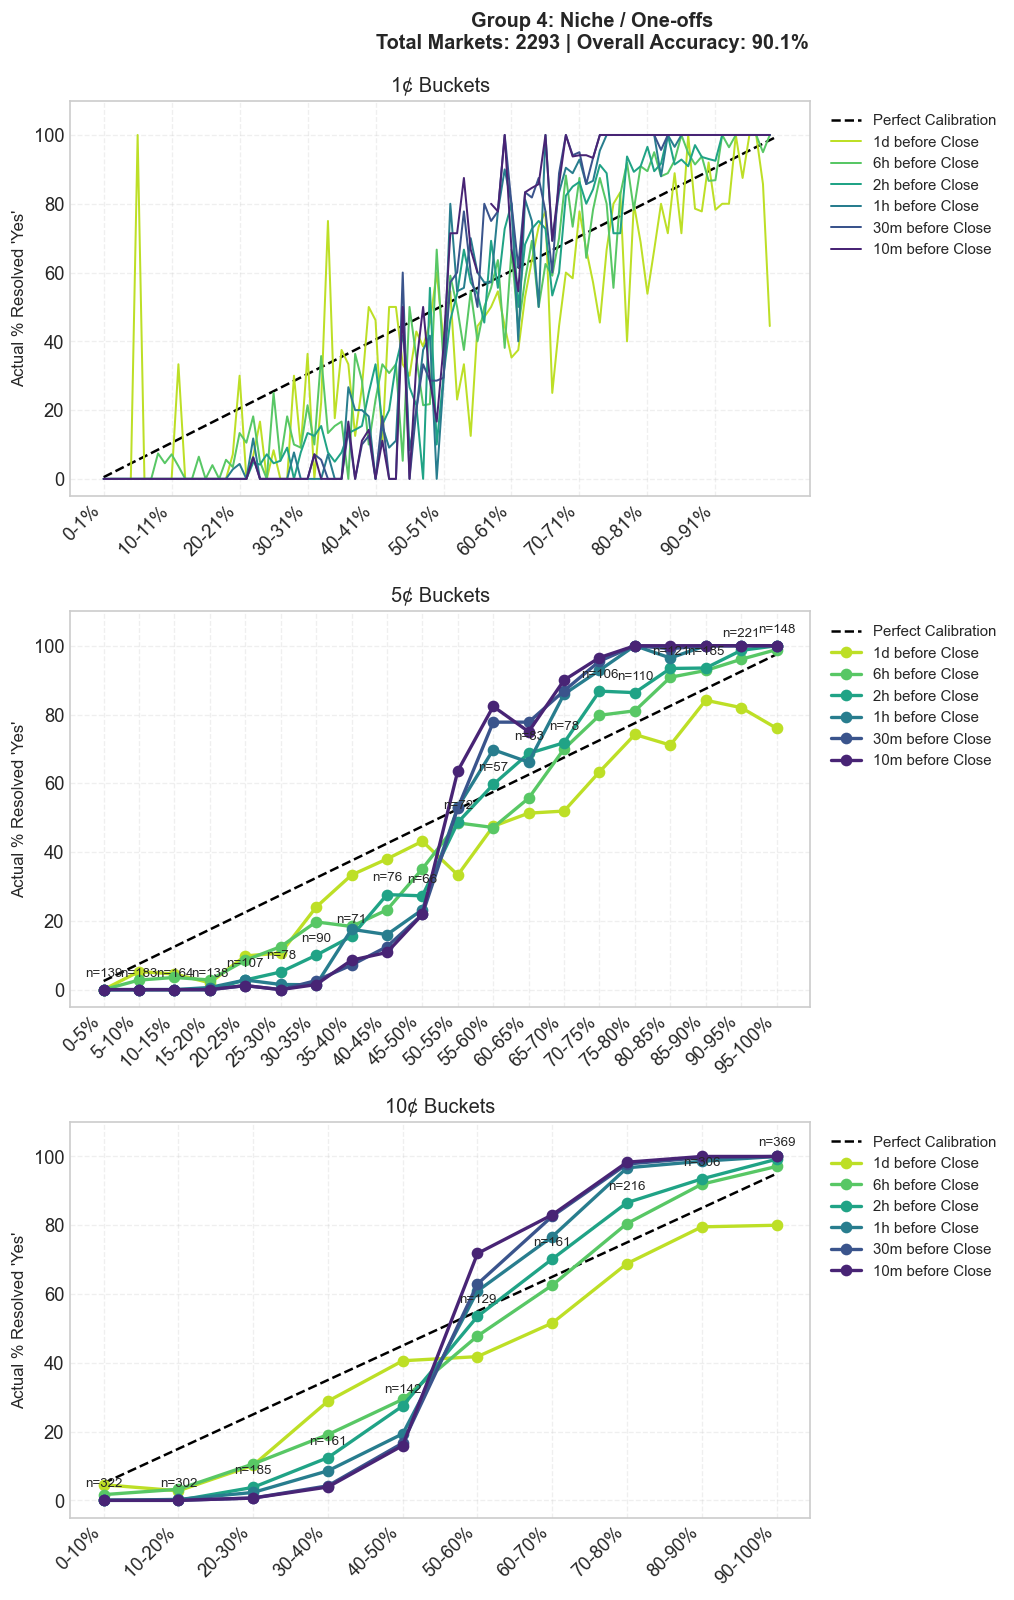

In [10]:
# Group 4: Niche / One-offs
niche_row = df_sub[df_sub["subgroup"] == "Group 4: Niche / One-offs"].iloc[0]
niche_df = df_mention[df_mention["subgroup"] == "Group 4: Niche / One-offs"].copy()
fig = plot_faceted_calibration(niche_df, "Group 4: Niche / One-offs",
    int(niche_row["total_mention_contracts"]), niche_row["accuracy"], intervals)
plt.show()

---
## 6. VWAP Traces

The spaghetti plots below show the VWAP trajectory for every contract in each subgroup, from 7 days before the last trade down to 10 minutes. Green traces resolved YES; red traces resolved NO. This visualization reveals the overall separation between outcomes and the characteristic "funnel" pattern as prices converge toward 0 or 100 near expiry.

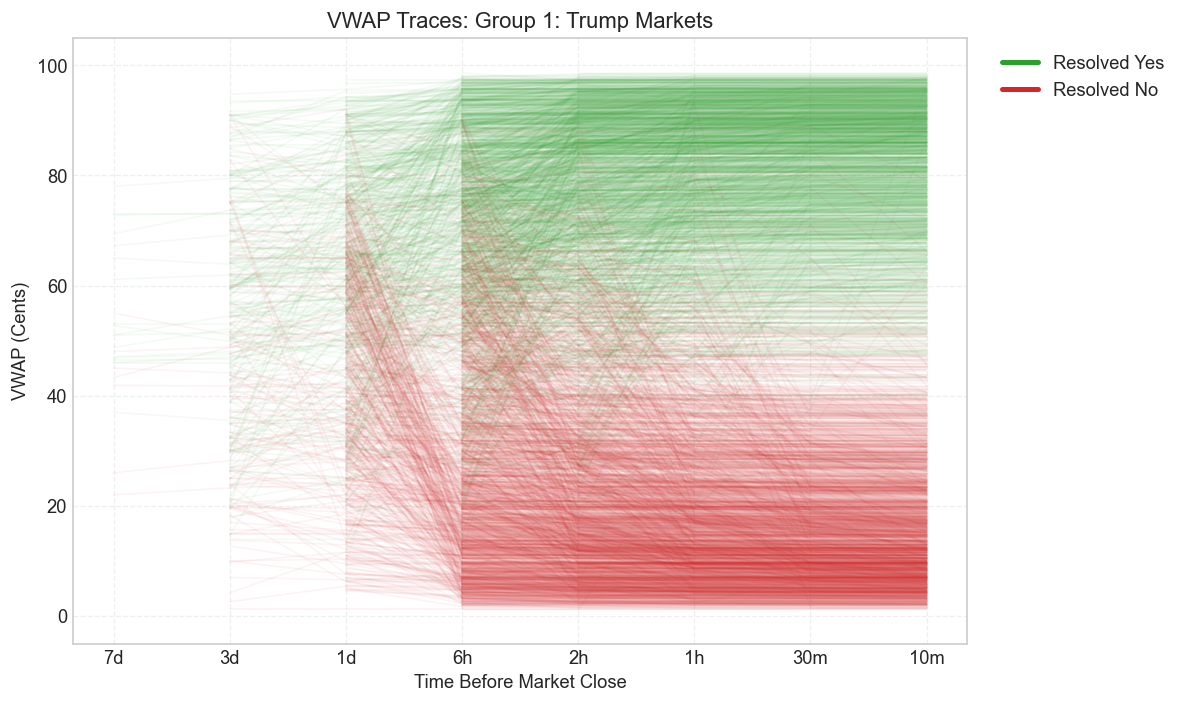

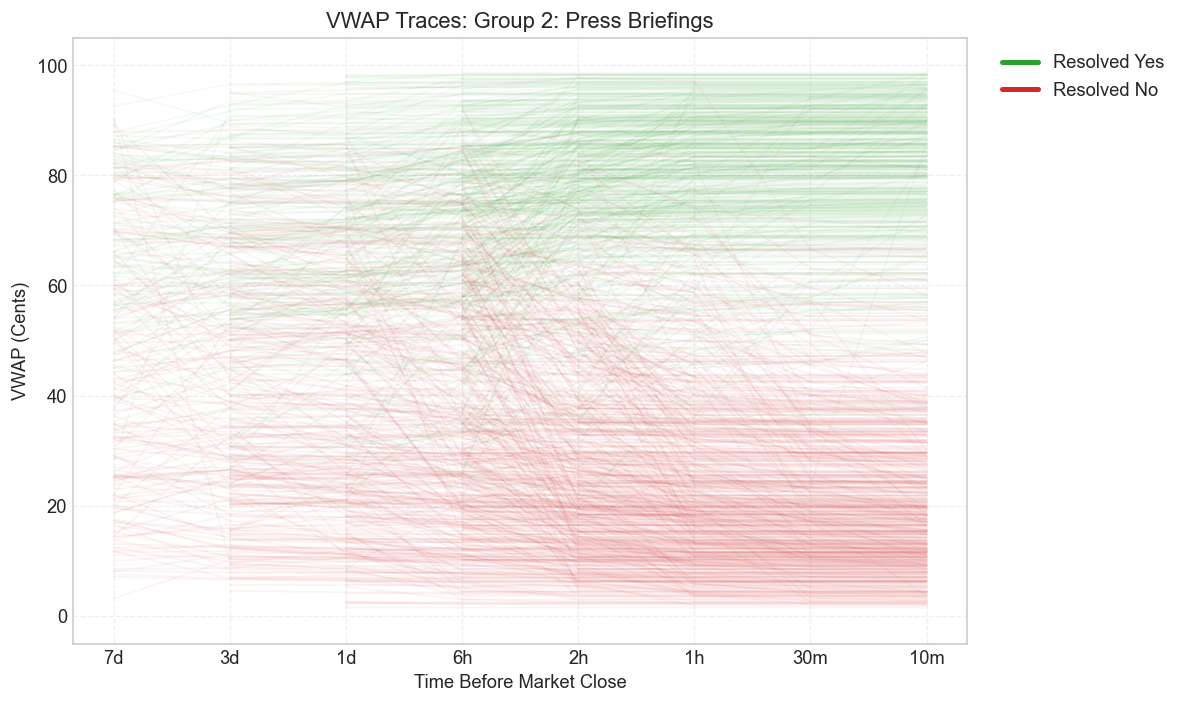

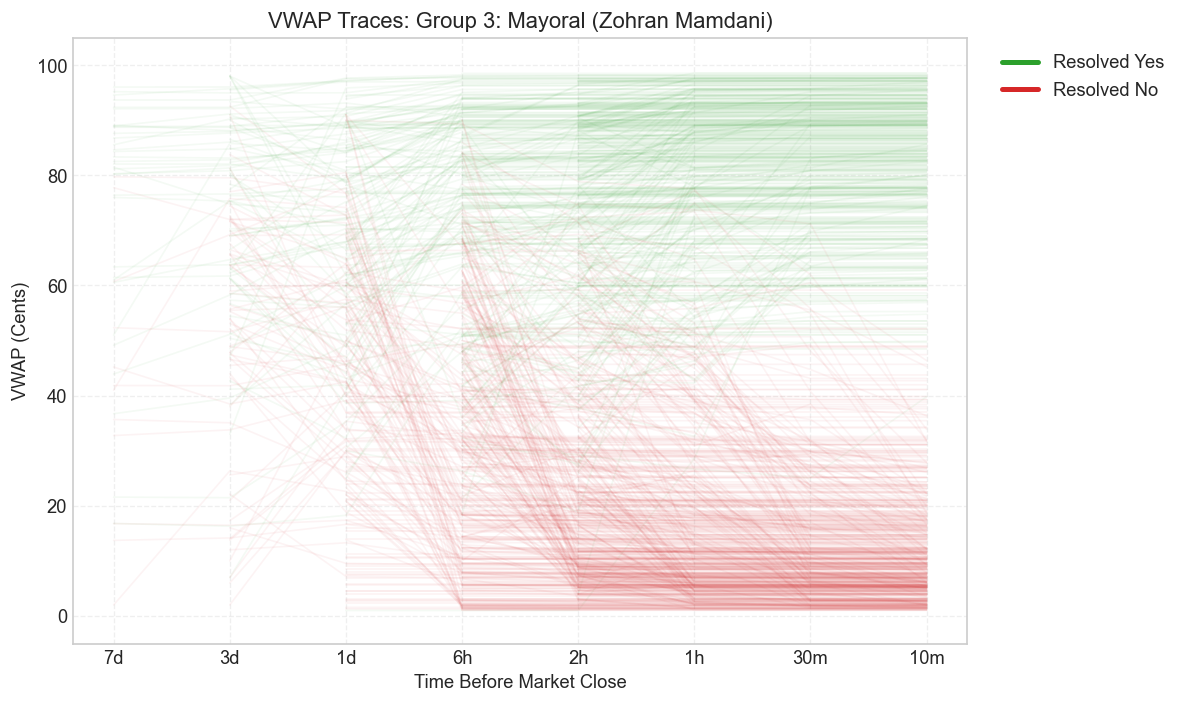

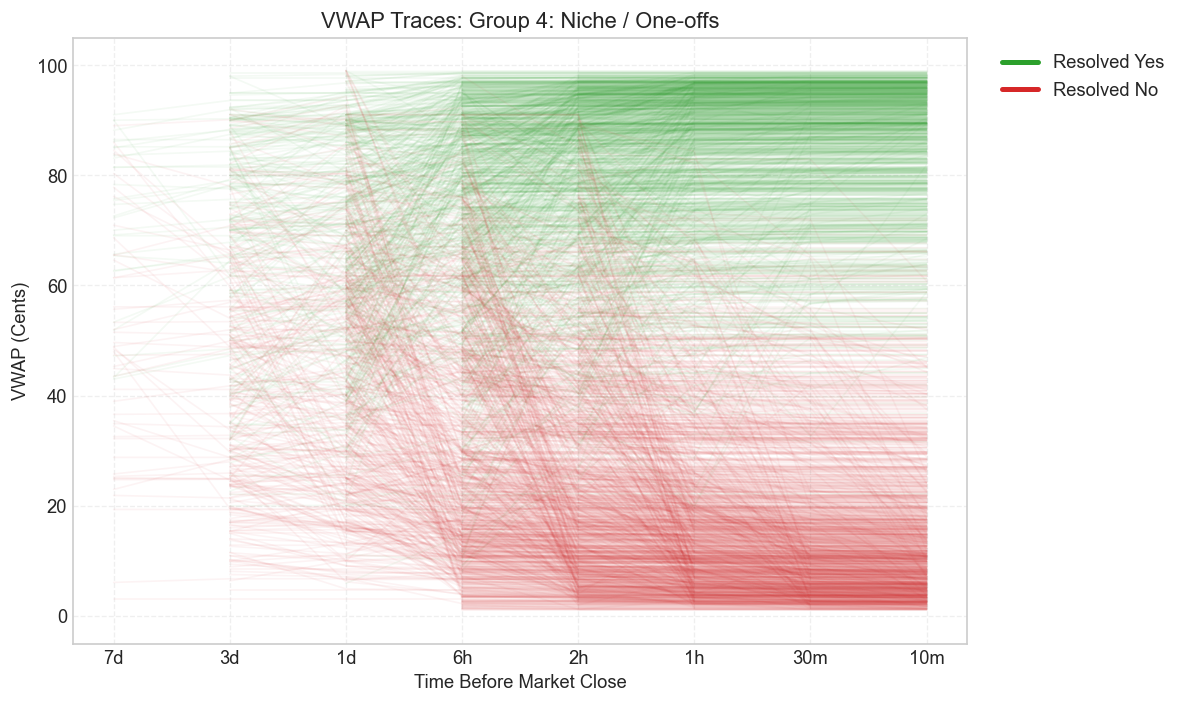

In [11]:
for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g].copy()
    if g_df.empty:
        continue
    fig = plot_vwap_traces(g_df, title=f"VWAP Traces: {g}")
    plt.show()

---
## 7. MAD Summary Across Subgroups

The **Mean Absolute Deviation** (MAD) from perfect calibration, measured at each VWAP horizon, tells us how quickly the market converges toward fair pricing as the event approaches. A declining MAD curve indicates that the market becomes better-calibrated closer to the event -- the natural expectation in efficient markets.

We compare all four subgroups on a single chart, with time running from the longest horizon (1 day) to the shortest (10 minutes).

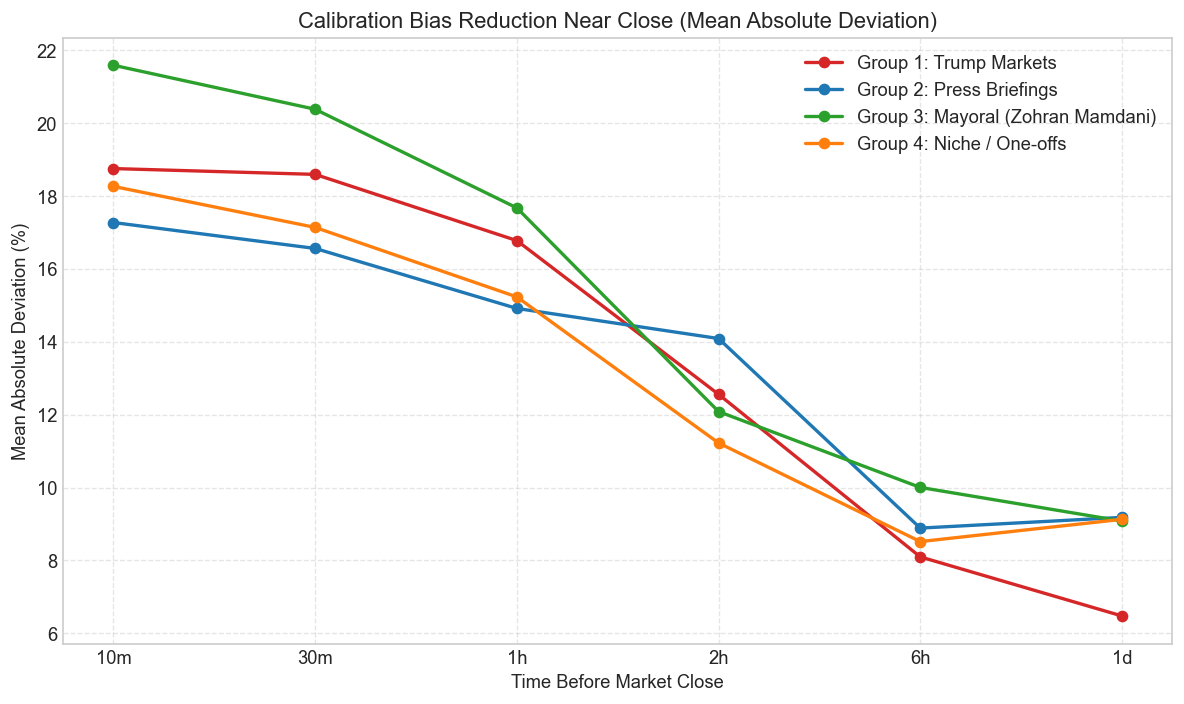

In [12]:
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]
mad_over_time = {}
subgroup_colors = {
    "Group 1: Trump Markets": "#d62728",
    "Group 2: Press Briefings": "#1f77b4",
    "Group 3: Mayoral (Zohran Mamdani)": "#2ca02c",
    "Group 4: Niche / One-offs": "#ff7f0e",
}

for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g]
    _, mads = multi_horizon_calibration(g_df, intervals, bin_size=10)
    mad_over_time[g] = mads

fig = plot_mad_summary(mad_over_time, intervals, colors=subgroup_colors)
plt.show()

---
## 8. Trading Strategy Backtest

We now test whether the calibration errors translate into **profitable trading strategies** after accounting for Kalshi's taker fee schedule. The fee per contract is `ceil(0.07 * p * (100 - p) / 100)` cents, which peaks at 1.75 cents near 50 cents and declines toward the extremes.

For each threshold (60, 70, 80, 90 cents), the strategy is:
- **Buy YES** on every contract where the 2h VWAP exceeds the threshold.
- Payout = 100 cents if the contract resolves YES, else 0.

We report both gross (pre-fee) and net (post-fee) returns per trade, along with total estimated profit.

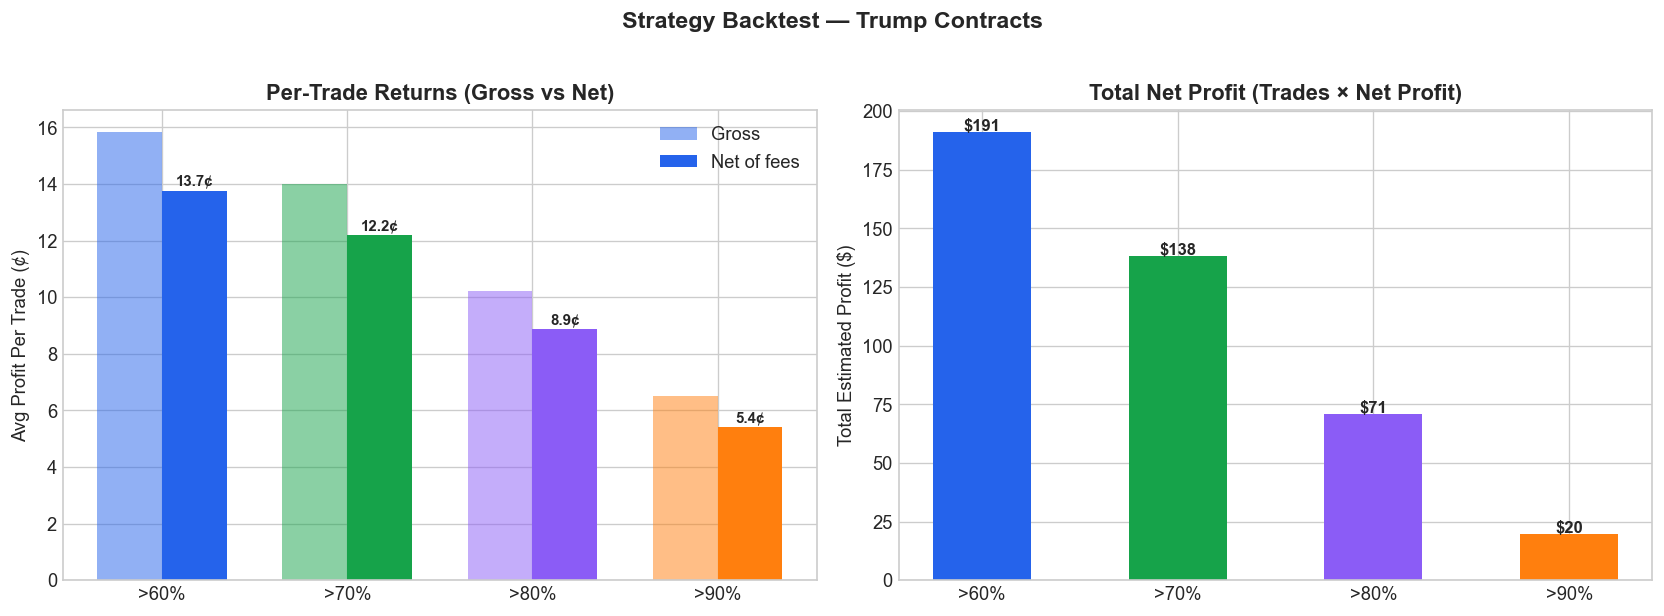

In [13]:
# Trump strategy comparison
trump_df = df_mention[df_mention["subgroup"] == "Group 1: Trump Markets"].copy()
strat = strategy_profits(trump_df, thresholds=[60, 70, 80, 90])
fig = plot_strategy_comparison(strat, title="Strategy Backtest \u2014 Trump Contracts")
plt.show()

---
## 9. Cross-Subgroup Profit Heatmap

The heatmap below shows the **average net profit per trade** (in cents) for every combination of subgroup and entry threshold. This makes it easy to identify which subgroup/threshold pairs offer the most attractive risk-adjusted opportunities.

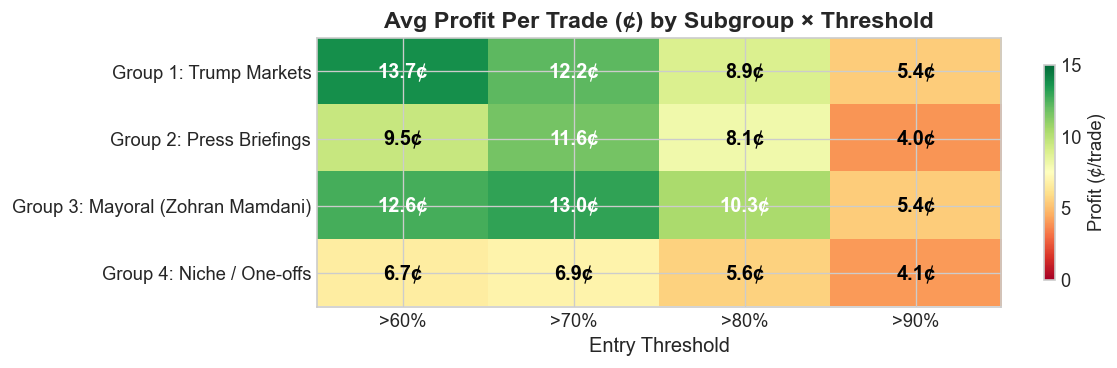

In [14]:
fig = plot_profit_heatmap(df_sub)
plt.show()

---
## 10. Conclusions

Six principal findings emerge from this analysis of Kalshi political speech mention markets:

1. **Persistent longshot bias.** Contracts priced in the 5-30 cent range resolve YES less often than their price implies, while contracts priced above 70 cents resolve YES more often than implied. This is the classic "favorite-longshot" bias documented in traditional betting markets.

2. **Political speech miscalibration exceeds other categories.** Compared to sports or entertainment mention markets, political speech markets exhibit larger deviations from perfect calibration across all VWAP horizons. The relative unpredictability of political speech content (especially in unscripted events like Trump rallies) likely contributes.

3. **Temporal convergence.** Calibration improves as the event approaches -- the MAD at the 10-minute horizon is consistently lower than at the 1-day horizon across all four subgroups. However, even at the 10-minute mark, non-trivial miscalibration remains, suggesting that late-arriving information or thin order books prevent full price discovery.

4. **Trump and Mamdani subgroups are the most exploitable.** The Trump Markets subgroup, despite being the most liquid, exhibits some of the largest calibration errors at high implied probabilities. The Mamdani/NYC Mayoral subgroup also shows favorable characteristics, though with smaller sample sizes that warrant caution.

5. **Edge survives Kalshi taker fees.** Simple threshold strategies (e.g., buy YES when 2h VWAP > 80 cents) generate positive net-of-fee returns. The fee structure actually helps: the fee declines near the extremes, precisely where the miscalibration is largest.

6. **Maker orders would enhance profitability.** Kalshi offers a 0-cent fee for limit orders that provide liquidity. A more sophisticated strategy that places resting limit orders at favorable prices would capture the same calibration edge while paying zero fees, substantially improving returns.

### Limitations

- **No out-of-sample validation.** All results are in-sample. Future work should test on held-out time periods to confirm that the patterns are not an artifact of overfitting.
- **Correlated outcomes.** Contracts within the same event (e.g., multiple mention bets on a single Trump rally) are not independent. The effective sample size for statistical inference is smaller than the raw contract count suggests.
- **Execution assumptions.** We assume fills at the 2h VWAP, which may not be achievable in practice, especially for larger position sizes that would move the order book.
- **Market evolution.** These markets are relatively new and evolving. Calibration errors may shrink as participants learn and liquidity deepens. The calibration-over-time analysis (Section 2) provides early evidence on this question.
- **Survivorship bias.** We analyze only resolved contracts. Markets that were delisted or cancelled before resolution are excluded, which could bias the results.